In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/processed/nsw_hourly.csv", index_col="SETTLEMENTDATE", parse_dates=True)
df.head()

,TOTALDEMAND,temperature_2m,relative_humidity_2m,is_holiday,hour,weekday
SETTLEMENTDATE,,,,,,
2024-01-01 00:00:00,6452.118182,20.2,72,1,0,0
2024-01-01 01:00:00,6133.330833,19.7,79,1,1,0
2024-01-01 02:00:00,5930.680000,19.8,79,1,2,0
2024-01-01 03:00:00,5821.847500,19.4,83,1,3,0
2024-01-01 04:00:00,5830.732500,19.4,84,1,4,0


In [4]:
from sklearn.linear_model import LinearRegression

In [5]:
X=df[["temperature_2m"]]
y=df[["TOTALDEMAND"]]

In [7]:
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[-60.02]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['temperature_2m']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[8577.71]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [8]:
print("w =", model.coef_)
print("b =", model.intercept_)

w = [[-60.0230197]]
b = [8577.71220405]


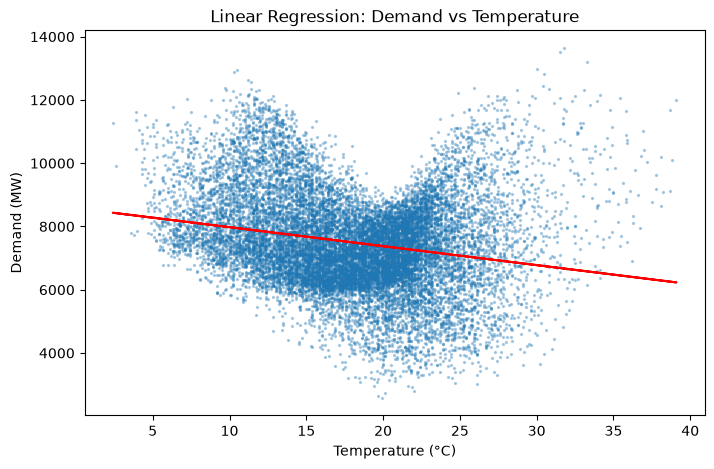

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(X["temperature_2m"], y, s=2, alpha=0.3)
plt.plot(X["temperature_2m"], model.predict(X), color="red")
plt.xlabel("Temperature (°C)")
plt.ylabel("Demand (MW)")
plt.title("Linear Regression: Demand vs Temperature")
plt.show()

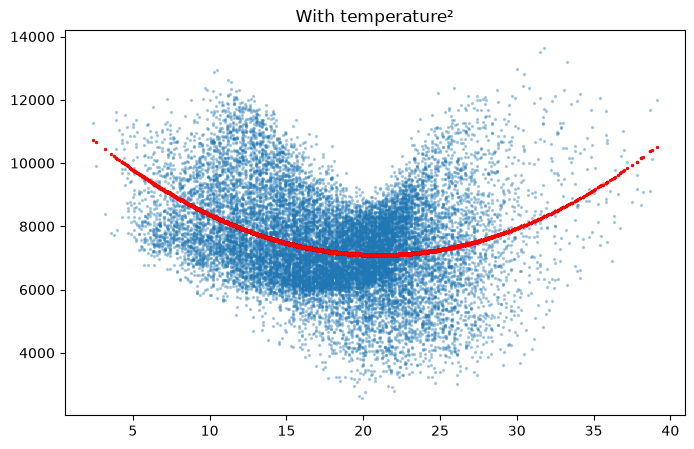

In [11]:
df["temp_squared"] = df["temperature_2m"] ** 2

X2 = df[["temperature_2m", "temp_squared"]]
model2 = LinearRegression()
model2.fit(X2, y)

plt.figure(figsize=(8, 5))
plt.scatter(X2["temperature_2m"], y, s=2, alpha=0.3)
plt.scatter(X2["temperature_2m"], model2.predict(X2), s=2, color="red")
plt.title("With temperature²")
plt.show()

In [13]:
print("OLD w:", model.coef_, " b:", model.intercept_)
print("NEW w:", model2.coef_, " b:", model2.intercept_)

OLD w: [[-60.0230197]]  b: [8577.71220405]
NEW w: [[-441.30653548   10.49288026]]  b: [11734.53865951]
